# EN4554 Assignment 2: CNNs (Task 1 of 4)


## Setup: data, split, normalisation, seeds

In [1]:
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

def set_seed(s=0):
    torch.manual_seed(s); np.random.seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

# CIFAR-10 training set only. The test set is NOT loaded (it is used once, in Task 4).
full = datasets.CIFAR10('./data', train=True, download=True)
X = torch.tensor(full.data).float() / 255          # (50000, 32, 32, 3)
X = X.permute(0, 3, 1, 2)                          # (50000, 3, 32, 32)
y = torch.tensor(full.targets)

# 45k train / 5k validation split with a fixed seed
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr, va = perm[:45000], perm[45000:]
Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]

# per-channel normalisation using TRAINING statistics only
mean = Xtr.mean((0, 2, 3), keepdim=True)
std  = Xtr.std((0, 2, 3), keepdim=True)
Xtr = (Xtr - mean) / std
Xva = (Xva - mean) / std

# flattened copies on the device for the MLP
Xtr_f = Xtr.flatten(1).to(device); ytr = ytr.to(device)
Xva_f = Xva.flatten(1).to(device); yva = yva.to(device)
print(Xtr_f.shape, Xva_f.shape)

Using device: cuda
torch.Size([45000, 3072]) torch.Size([5000, 3072])


## Task 1(a): Layers with explicit forward/backward (no autograd)
Each layer stores what it needs in `forward` and uses it in `backward`.
The weights use `std = sqrt(gain / n_in)` (He init when `gain=2`).

In [3]:
class Linear:
    def __init__(self, n_in, n_out, gain=2.0, dtype=torch.float32, device='cpu'):
        self.W = torch.randn(n_in, n_out, dtype=dtype, device=device) * np.sqrt(gain / n_in)
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
    def forward(self, x):
        self.x = x                       # cache input for backward
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout        # dL/dW
        self.db = dout.sum(0)            # dL/db
        return dout @ self.W.T           # dL/dx
    def params(self):
        return [(self.W, self.dW), (self.b, self.db)]

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask
    def params(self): return []

class Sigmoid:                           # only needed for Task 1(d)
    def forward(self, x):
        self.out = 1 / (1 + torch.exp(-x))
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)
    def params(self): return []

In [4]:
def softmax_ce(logits, y):
    # returns mean loss and dL/dlogits
    z = logits - logits.max(1, keepdim=True).values      # for numerical stability
    p = z.exp(); p = p / p.sum(1, keepdim=True)
    n = len(y)
    loss = -torch.log(p[torch.arange(n), y]).mean()
    d = p.clone(); d[torch.arange(n), y] -= 1
    return loss, d / n


In [5]:
class MLP:
    def __init__(self, sizes, act=ReLU, gain=2.0, dtype=torch.float32, device=device):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i+1], gain, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(act())
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def backward(self, dout):
        for l in reversed(self.layers): dout = l.backward(dout)
    def params(self):
        return [pg for l in self.layers for pg in l.params()]


In [6]:
def accuracy(model, X, y):
    return (model.forward(X).argmax(1) == y).float().mean().item()

## Task 1(b): Gradient checks
Done in **float64** on a tiny MLP and a small random batch, because float32 finite differences are too noisy.
We compare our backward pass with (1) autograd and (2) centred finite differences, `(L(w+eps) - L(w-eps)) / (2 eps)`.

In [8]:
set_seed(0)
model = MLP([20, 16, 10], dtype=torch.float64, device='cpu')
xb = torch.randn(8, 20, dtype=torch.float64)
yb = torch.randint(0, 10, (8,))

# our gradients
loss, d = softmax_ce(model.forward(xb), yb)
model.backward(d)
mine = [g.clone() for _, g in model.params()]

# autograd gradients (same weights)
ps = [p.clone().requires_grad_() for p, _ in model.params()]
h = torch.relu(xb @ ps[0] + ps[1])
l = F.cross_entropy(h @ ps[2] + ps[3], yb)
l.backward()
auto = [p.grad for p in ps]

In [10]:
# centred finite differences, one weight at a time
def num_grad(p, eps=1e-6):
    g = torch.zeros_like(p)
    pf, gf = p.view(-1), g.view(-1)      # views: editing pf edits the model weight
    for i in range(pf.numel()):
        old = pf[i].item()
        pf[i] = old + eps; lp = softmax_ce(model.forward(xb), yb)[0].item()
        pf[i] = old - eps; lm = softmax_ce(model.forward(xb), yb)[0].item()
        pf[i] = old
        gf[i] = (lp - lm) / (2 * eps)
    return g
num = [num_grad(p) for p, _ in model.params()]

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm())).item()


In [11]:
names = ['W1', 'b1', 'W2', 'b2']
print(f"{'param':6s} {'vs autograd':>12s} {'vs finite diff':>15s}  allclose(auto)  allclose(num)")
for n, m, a, f in zip(names, mine, auto, num):
    print(f"{n:6s} {rel_err(m, a):12.2e} {rel_err(m, f):15.2e}  "
          f"{torch.allclose(m, a, atol=1e-8)!s:>14}  {torch.allclose(m, f, atol=1e-6)!s:>13}")

param   vs autograd  vs finite diff  allclose(auto)  allclose(num)
W1         6.24e-17        1.05e-09            True           True
b1         3.07e-17        5.98e-10            True           True
W2         4.05e-17        8.98e-10            True           True
b2         6.47e-17        8.56e-10            True           True



The relative errors between the manually calculated gradients and autograd gradients are extremely small, approximately \\(10^{-17}\\). The relative errors compared with centred finite differences are also very small, approximately \\(10^{-9}\\). All parameters return `True` for `torch.allclose()` in both comparisons.

Based on that, The manual gradients for \\(W_1\\), \\(b_1\\), \\(W_2\\), and \\(b_2\\) match the autograd and finite-difference gradients within the specified tolerances. This verifies the correctness of the implemented backpropagation calculations.

## Task 1(c): Train the MLP with SGD on flattened CIFAR-10
3072-512-256-10 MLP, mini-batch SGD (batch 128, lr 0.01), 15 epochs.

In [12]:
def train_mlp(model, epochs=15, lr=0.01, bs=128):
    losses, val_accs = [], []
    for ep in range(epochs):
        idx = torch.randperm(len(Xtr_f), device=device)
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]
            loss, d = softmax_ce(model.forward(Xtr_f[b]), ytr[b])
            model.backward(d)
            for p, g in model.params():
                p -= lr * g                      # plain SGD step
            losses.append(loss.item())
        val_accs.append(accuracy(model, Xva_f, yva))
        print(f"epoch {ep+1:2d}  val acc {val_accs[-1]:.4f}")
    return losses, val_accs

In [14]:
set_seed(0)
mlp = MLP([3072, 512, 256, 10], device=device)
losses, val_accs = train_mlp(mlp, epochs=50)

epoch  1  val acc 0.4104
epoch  2  val acc 0.4318
epoch  3  val acc 0.4486
epoch  4  val acc 0.4714
epoch  5  val acc 0.4736
epoch  6  val acc 0.4818
epoch  7  val acc 0.4896
epoch  8  val acc 0.4858
epoch  9  val acc 0.4998
epoch 10  val acc 0.4902
epoch 11  val acc 0.4950
epoch 12  val acc 0.4920
epoch 13  val acc 0.4972
epoch 14  val acc 0.5084
epoch 15  val acc 0.5040
epoch 16  val acc 0.5004
epoch 17  val acc 0.5046
epoch 18  val acc 0.5114
epoch 19  val acc 0.4998
epoch 20  val acc 0.5058
epoch 21  val acc 0.5036
epoch 22  val acc 0.5098
epoch 23  val acc 0.5060
epoch 24  val acc 0.5114
epoch 25  val acc 0.5088
epoch 26  val acc 0.5008
epoch 27  val acc 0.5086
epoch 28  val acc 0.5094
epoch 29  val acc 0.5018
epoch 30  val acc 0.4886
epoch 31  val acc 0.5098
epoch 32  val acc 0.4946
epoch 33  val acc 0.5070
epoch 34  val acc 0.5014
epoch 35  val acc 0.5098
epoch 36  val acc 0.5142
epoch 37  val acc 0.4988
epoch 38  val acc 0.5124
epoch 39  val acc 0.5122
epoch 40  val acc 0.5002


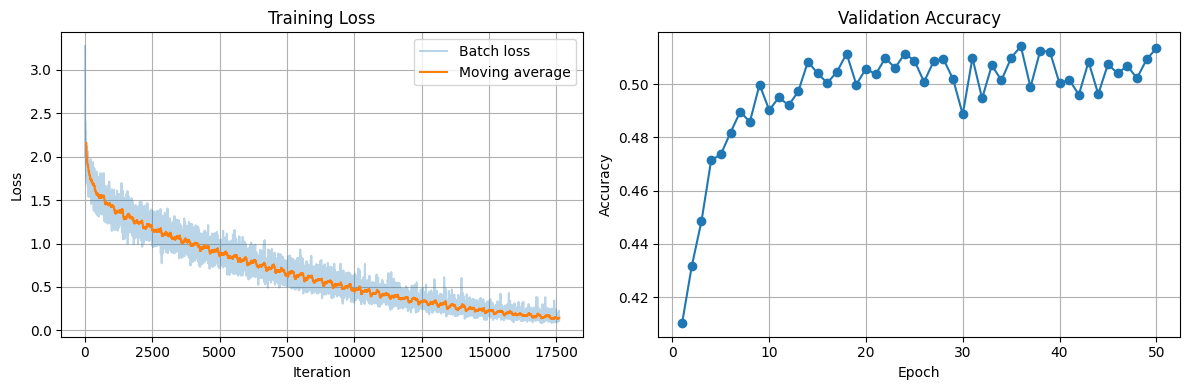


Final validation accuracy: 0.5134 (51.34%)
Initial batch loss: 3.2745
Final batch loss: 0.1506


In [17]:

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Training loss
smooth = np.convolve(losses, np.ones(50) / 50, mode='valid')
ax[0].plot(losses, alpha=0.3, label='Batch loss')
ax[0].plot(range(49, len(losses)), smooth, label='Moving average')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Loss')
ax[0].set_title('Training Loss')
ax[0].legend()
ax[0].grid(True)

# Validation accuracy
ax[1].plot(range(1, len(val_accs) + 1), val_accs, marker='o')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].set_title('Validation Accuracy')
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Print results
# print("\nValidation Accuracy by Epoch")
# for epoch, acc in enumerate(val_accs, start=1):
#     print(f"Epoch {epoch}: {acc:.4f} ({acc * 100:.2f}%)")

print(f"\nFinal validation accuracy: {val_accs[-1]:.4f} "
      f"({val_accs[-1] * 100:.2f}%)")

print(f"Initial batch loss: {losses[0]:.4f}")
print(f"Final batch loss: {losses[-1]:.4f}")


Results

- Final validation accuracy: 51.34%
- Initial batch loss: 3.2745
- Final batch loss: 0.1506



The training loss decreased from 3.2745 to 0.1506, indicating that the MLP learned to classify the training images more accurately. The final validation accuracy was 51.34%, meaning the model correctly classified about half of the validation images. The difference between the low final batch loss and the validation accuracy suggests that the model may be overfitting to the training data.



## Task 1(d): Per-layer gradient norm at initialisation, 10-layer MLP
Ten `Linear` layers (3072 -> 256 x 9 -> 10), one batch of 256 training images, no training.
Each activation uses its usual initialisation: He (`gain=2`) for ReLU and Xavier-style (`gain=1`) for sigmoid.

In [18]:
def layer_grad_norms(act, gain):
    set_seed(0)
    net = MLP([3072] + [256] * 9 + [10], act=act, gain=gain, device=device)
    loss, d = softmax_ce(net.forward(Xtr_f[:256]), ytr[:256])
    net.backward(d)
    return [l.dW.norm().item() for l in net.layers if isinstance(l, Linear)]

In [19]:
g_sig = layer_grad_norms(Sigmoid, 1.0)
g_relu = layer_grad_norms(ReLU, 2.0)

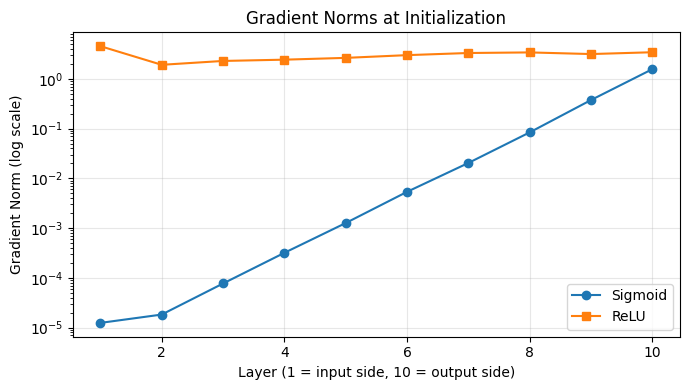

Layer             Sigmoid           ReLU
----------------------------------------
1            1.241838e-05   4.528123e+00
2            1.825629e-05   1.911372e+00
3            7.686698e-05   2.284997e+00
4            3.179764e-04   2.424104e+00
5            1.262096e-03   2.634328e+00
6            5.348971e-03   2.989318e+00
7            2.035817e-02   3.300320e+00
8            8.384722e-02   3.391168e+00
9            3.747588e-01   3.143253e+00
10           1.564552e+00   3.419592e+00


In [21]:

plt.figure(figsize=(7, 4))

plt.semilogy(range(1, 11), g_sig, marker='o', label='Sigmoid')
plt.semilogy(range(1, 11), g_relu, marker='s', label='ReLU')

plt.xlabel('Layer (1 = input side, 10 = output side)')
plt.ylabel('Gradient Norm (log scale)')
plt.title('Gradient Norms at Initialization')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print gradient norms
print(f"{'Layer':<10}{'Sigmoid':>15}{'ReLU':>15}")
print("-" * 40)

for i, (sig, relu) in enumerate(zip(g_sig, g_relu), start=1):
    print(f"{i:<10}{sig:>15.6e}{relu:>15.6e}")


### Interpretation for Task 1(d)

The Sigmoid network shows a significant decrease in gradient norms toward the input layer. The gradient norm decreases from approximately 1.56 at layer 10 to \\(1.24 \times 10^{-5}\\) at layer 1. This happens because the Sigmoid derivative is at most 0.25, so gradients can shrink as they propagate backward through multiple layers. Consequently, earlier layers may learn very slowly.

In contrast, the ReLU network maintains gradient norms within a relatively stable range of approximately 1.91 to 4.53. ReLU has a derivative of 1 for positive inputs, and He initialization helps preserve signal and gradient magnitudes through the network. Therefore, ReLU reduces the vanishing gradient problem and supports more effective training of deep networks.

Conclusion: ReLU is more suitable than Sigmoid for this deep MLP because it maintains stronger gradients in earlier layers, helping them learn more effectively.